In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


PERFORMING EDA!!!!!!!!!!!!!


In [7]:
df = pd.read_csv("/content/Salary_Data.csv")
df

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0
5,2.9,56642.0
6,3.0,60150.0
7,3.2,54445.0
8,3.2,64445.0
9,3.7,57189.0


In [11]:
df.head()

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


In [12]:
df.tail()


,YearsExperience,Salary
25,9.0,105582.0
26,9.5,116969.0
27,9.6,112635.0
28,10.3,122391.0
29,10.5,121872.0


In [14]:
df.shape

(30, 2)

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes


In [16]:
df.describe()

,YearsExperience,Salary
count,30.000000,30.000000
mean,5.313333,76003.000000
std,2.837888,27414.429785
min,1.100000,37731.000000
25%,3.200000,56720.750000
50%,4.700000,65237.000000
75%,7.700000,100544.750000
max,10.500000,122391.000000


In [17]:
df.isnull().sum()

,0
YearsExperience,0
Salary,0


In [18]:
df["Salary"].describe()

,Salary
count,30.000000
mean,76003.000000
std,27414.429785
min,37731.000000
25%,56720.750000
50%,65237.000000
75%,100544.750000
max,122391.000000


NOW COMING TO THE MAIN POINT CHEKING SCATTERPLOT


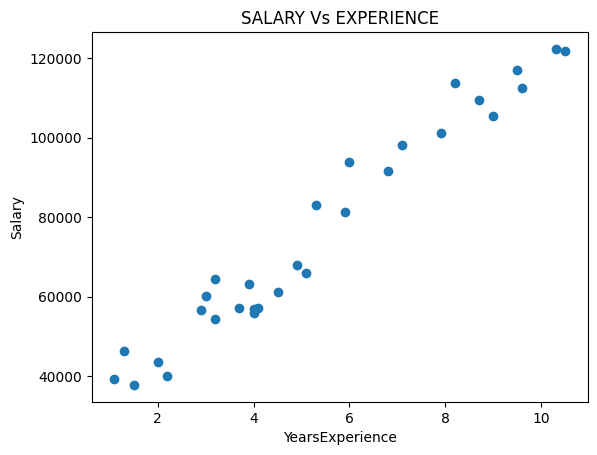

In [22]:
plt.scatter(df["YearsExperience"],df["Salary"])
plt.xlabel("YearsExperience")
plt.ylabel("Salary")
plt.title("SALARY Vs EXPERIENCE")
plt.show()

In [24]:
#input column
#X train mtlb X ka hi adha hissa traning ko dena aur X test main adha data testing main dena
# 80% training pr dete 20% testing main
#randomm state 42,90,0 common rkh lete wrna tou 1 to 100 main se koi si bhi rkh skte
X =df.drop(["Salary"],axis=1)
#output column
y =df["Salary"]
#X se salary drop krwa kr y main daaal di column main


In [27]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state =42)

In [32]:
y_test

,Salary
27,112635.0
15,67938.0
23,113812.0
17,83088.0
8,64445.0
9,57189.0


In [33]:
y_train

,Salary
28,122391.0
24,109431.0
12,56957.0
0,39343.0
4,39891.0
16,66029.0
5,56642.0
13,57081.0
11,55794.0
22,101302.0


In [34]:
X_train

,YearsExperience
28,10.3
24,8.7
12,4.0
0,1.1
4,2.2
16,5.1
5,2.9
13,4.1
11,4.0
22,7.9


In [35]:
X_test

,YearsExperience
27,9.6
15,4.9
23,8.2
17,5.3
8,3.2
9,3.7


**NOW WE'RE CREATING OR CALLING OUR MODEL**

In [36]:
model = LinearRegression()

In [37]:
#fitiing model on our training data
model.fit(X_train,y_train)

LinearRegression()

### **MODEL TESTING**


In [40]:
# prediction
y_pred = model.predict(X_test) #input(yearsexperience) jo hmne usko di us pr usne predict kr k di salarry!!!!! ka test main data rkha tha
y_pred

array([115790.21011287,  71498.27809463, 102596.86866063,  75267.80422384,
        55477.79204548,  60189.69970699])

In [42]:
#dataframe bnaya h yahan
pd.DataFrame({'y_test':y_test, 'y_pred':y_pred,"MAE":(y_test-y_pred)}) #MEANABSOLUTEERROR #difference in actual and predictive value

,y_test,y_pred,MAE
27,112635.0,115790.210113,-3155.210113
15,67938.0,71498.278095,-3560.278095
23,113812.0,102596.868661,11215.131339
17,83088.0,75267.804224,7820.195776
8,64445.0,55477.792045,8967.207955
9,57189.0,60189.699707,-3000.699707


In [45]:
model.predict([[10]])
#if someone has 10 years of experience then their salary should be this
#thats what this model is predicting

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([119559.73624209])

## **Model intercept and slope, make an equation**

In [46]:
# take out model intercept and slop, make an equation
print(model.intercept_)#intercept
print(model.coef_)#slope
print('y = ',model.coef_, '* X', '+', model.intercept_)#line equation

25321.583011776813
[9423.81532303]
y =  [9423.81532303] * X + 25321.583011776813


## **Evaluation Matrix**
ACCURACIES

In [47]:
print('MSE = ', mean_squared_error(y_test, y_pred ))
print('RMSE = ', np.sqrt(mean_squared_error(y_test, y_pred )))
print('R2 = ', r2_score(y_test, y_pred ))

MSE =  49830096.85590839
RMSE =  7059.04362190151
R2 =  0.9024461774180497


## **Plot Model on Train and Test data**

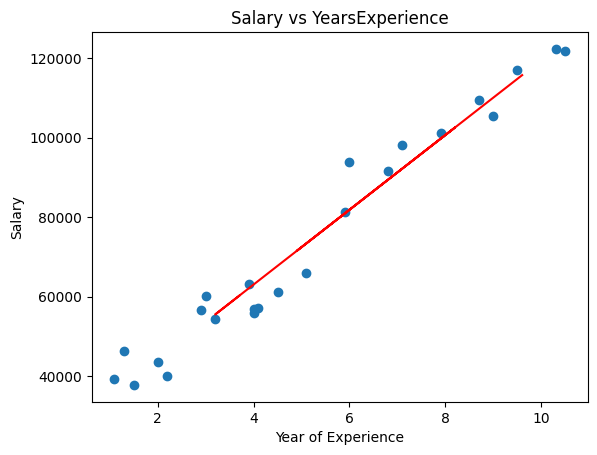

In [50]:
#on  a train data
plt.scatter(X_train,y_train)
plt.plot(X_test,y_pred,color='r')
plt.title("Salary vs YearsExperience")
plt.xlabel("Year of Experience")
plt.ylabel("Salary")
plt.show()

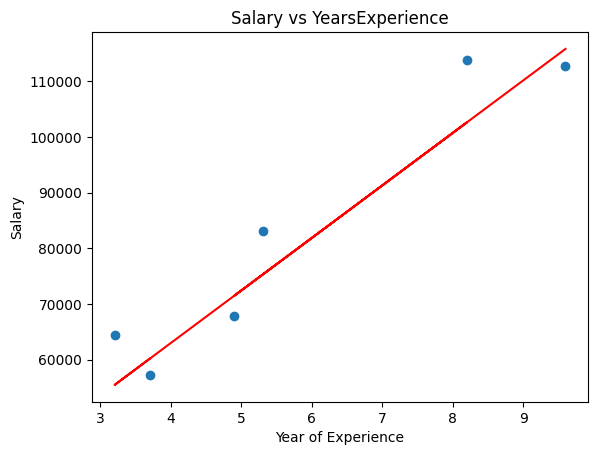

In [51]:
#on a test data
plt.scatter(X_test,y_test)
plt.plot(X_test,y_pred,color='r')
plt.title("Salary vs YearsExperience")
plt.xlabel("Year of Experience")
plt.ylabel("Salary")
plt.show()